In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd

repo = Path.cwd().parent
# Notebook 10's run, then the reruns of the Runs that apir-adapter fixes changed: notebook 12 (S3 and M1, commit
# a053272) and notebook 13 (S3 again, commit after it). A Run in a later run replaces the Run of the same name in an
# earlier one, as a resumed Run's latest attempt does.
RAW = repo / "results/raw"
RUNS = [RAW / "rq4-day-20261111", RAW / "rq4-rerun-20261111", RAW / "rq4-rerun-s3-20261111"]
manifest, source = {}, {}
for run_dir in RUNS:
    meta = json.loads((run_dir / "meta.json").read_text())
    print(f"run {meta['run_id']} at {meta['git_sha'][:7]}, citable={meta['citable']}, dirty={meta['dirty']}")
    assert meta["citable"] and not meta["dirty"], "only a citable run from a clean tree is analysed"
    for line in (run_dir / "manifest.jsonl").read_text().splitlines():
        row = json.loads(line)
        manifest[row["name"]], source[row["name"]] = row, run_dir.name

def num(x):
    return 0.0 if x is None else float(x)

recs = []
for name, m in manifest.items():
    if m["outcome"] != "ok":
        continue
    run = m["run"]
    for line in (repo / "results/raw" / source[name] / f"{name}.jsonl").read_text().splitlines():
        r = json.loads(line)
        if r["is_warmup"]:
            continue
        x = r["metrics"]
        row = {k: run[k] for k in ("arm", "kind", "fault", "policy", "fault_prob", "replicas_cheat", "db_bytes")}
        row.update(phase=r["phase"], faulted=r["faulted"], detected=r["detected"], correct=r["correct"],
                   outcome=r["recovery_outcome"], attempts=r["recovery_attempts"])
        if r["phase"] == "online":
            # Fault-free latency on one machine (spec 6, latency_e2e without the network terms): the two servers
            # of M0 and M1 answer in parallel, so their slower answer counts.
            row["first_s"] = (num(x["query_gen_s"]) + max(num(s) for s in x["server_answer_s"])
                              + num(x["client_recover_s"]) + num(x["client_verify_s"]))
            row["recovery_s"] = num(x["recovery_s"])
            row["time_to_end_s"] = row["first_s"] + row["recovery_s"]   # to a verified record, or to abort
            row["first_bytes"] = num(x["up_bytes"]) + num(x["down_bytes"])
            row["extra_bytes"] = num(x["recovery_up_bytes"]) + num(x["recovery_down_bytes"])
        else:
            row["offline_s"] = sum(num(x[k]) for k in ("public_params_s", "server_preproc_s",
                                                         "server_preproc_proof_s", "client_offline_s"))
        recs.append(row)
df = pd.DataFrame(recs)
not_ok = {n: m["outcome"] for n, m in manifest.items() if m["outcome"] != "ok"}
print(f"{len(manifest)} Runs, {len(not_ok)} not ok; {len(df)} records after warm-ups")
for d, n in pd.Series(source).value_counts().items():
    print(f"  {n:3d} Runs from {d}")
for n, o in not_ok.items():
    print(f"  {o}: {n}")

run rq4-day-20261111 at 29bcc2a, citable=True, dirty=False
run rq4-rerun-20261111 at a053272, citable=True, dirty=False
run rq4-rerun-s3-20261111 at b353acc, citable=True, dirty=False


116 Runs, 0 not ok; 46912 records after warm-ups
  100 Runs from rq4-day-20261111
    8 Runs from rq4-rerun-s3-20261111
    8 Runs from rq4-rerun-20261111


In [2]:
RNG = np.random.default_rng(1234)
B = 10_000                                            # spec 6: 10 000 bootstrap resamples

def boot_ci(values, stat=np.median):
    v = np.asarray(values, float)
    if len(v) == 0:
        return (np.nan, np.nan, np.nan)
    idx = RNG.integers(0, len(v), size=(B, len(v)))
    s = stat(v[idx], axis=1)
    return (float(stat(v)), float(np.quantile(s, 0.025)), float(np.quantile(s, 0.975)))

def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    c = (p + z * z / (2 * n)) / (1 + z * z / n)
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return (max(0.0, c - h), min(1.0, c + h))

VERIFIABLE = ["S1", "S2", "S3", "S4", "M1"]
BASELINES = ["S0-go", "S0-cpp", "M0"]
ARMS = ["S0-go", "S0-cpp", "S1", "S2", "S3", "S4", "M0", "M1"]
POLICIES = ["abort", "switch_replica", "re_preprocess"]
FAULTS = ["flip_answer_bit", "wrong_record", "stale_record", "drop_server"]

# Detection: the first answer of every faulted trial, whatever the policy, and every faulted offline repetition.
# A baseline has no check, so it detects nothing by construction and gets no rate. Its drop_server answers abort
# because nothing arrives, not because a check failed.
pd.set_option("display.width", 200)
first = df[(df.kind == "trials") & df.faulted.astype(bool)]
det = (first.groupby(["arm", "fault"]).agg(n=("detected", "size"), detected=("detected", "sum"),
                                            silent_wrong=("outcome", lambda o: int((o == "silent_wrong").sum())),
                                            aborted=("outcome", lambda o: int((o == "aborted").sum())))
       .reset_index())
off = df[(df.kind == "offline") & df.faulted.astype(bool)]
det = pd.concat([det, off.groupby(["arm", "fault"]).agg(n=("detected", "size"), detected=("detected", "sum"))
                 .reset_index()])
verifiable = det.arm.isin(VERIFIABLE)
det.loc[~verifiable, "detected"] = np.nan
det["rate"] = det.detected / det.n
det[["lo95", "hi95"]] = [wilson(k, n) if v else (np.nan, np.nan) for k, n, v in zip(det.detected, det.n, verifiable)]
print("Detection of faulted first answers (trials) and faulted offline phases, Wilson 95 % CI "
      "(n/a: baselines have no check; offline phases have no outcome)")
print(det.round(3).to_string(index=False, na_rep="n/a"))

# False rejects: an honest first answer the client rejected, over every sweep query.
honest = df[(df.kind == "sweep") & ~df.faulted.astype(bool)]
fr = honest.groupby("arm").agg(honest=("detected", "size"), rejected=("detected", "sum"))
print("\nFalse rejects among honest sweep answers (spec: should never happen)")
print(fr.to_string())

Detection of faulted first answers (trials) and faulted offline phases, Wilson 95 % CI (n/a: baselines have no check; offline phases have no outcome)
   arm           fault   n detected  silent_wrong  aborted rate  lo95  hi95
    M0     drop_server 100      n/a           0.0    100.0  n/a   n/a   n/a
    M0 flip_answer_bit 100      n/a         100.0      0.0  n/a   n/a   n/a
    M0    stale_record 100      n/a         100.0      0.0  n/a   n/a   n/a
    M0    wrong_record 100      n/a         100.0      0.0  n/a   n/a   n/a
    M1     drop_server 200      200           0.0    100.0  1.0 0.981   1.0
    M1 flip_answer_bit 200      200           0.0    100.0  1.0 0.981   1.0
    M1    stale_record 200      200           0.0    100.0  1.0 0.981   1.0
    M1    wrong_record 200      200           0.0    100.0  1.0 0.981   1.0
S0-cpp     drop_server 100      n/a           0.0    100.0  n/a   n/a   n/a
S0-cpp flip_answer_bit 100      n/a         100.0      0.0  n/a   n/a   n/a
S0-cpp    stal

In [3]:
# F12: what a rejection costs, per fault and policy, as a multiple of the arm's fault-free latency
# (spec 6, recovery_cost_ratio). Trials give abort and switch_replica for every fault. re_preprocess comes from
# the f = 0.1 sweep (wrong_record), where a rejected query is followed by a fresh offline phase.
base = (df[(df.kind == "sweep") & (df.fault_prob == 0)].groupby("arm")
        .agg(latency_s=("first_s", "median"), bytes=("first_bytes", "median")))
rows = []
def add(sel, arm, fault, policy):
    if len(sel) == 0:
        return
    t = boot_ci(sel.time_to_end_s / base.latency_s[arm])
    b = boot_ci(sel.extra_bytes / base.bytes[arm])
    oc = sel.outcome.value_counts()
    rows.append(dict(arm=arm, fault=fault, policy=policy, n=len(sel), ratio=t[0], ratio_lo=t[1], ratio_hi=t[2],
                     time_s=float(sel.time_to_end_s.median()), extra_bytes_ratio=b[0], extra_lo=b[1], extra_hi=b[2],
                     recovered=int(oc.get("recovered", 0)), aborted=int(oc.get("aborted", 0)),
                     silent_wrong=int(oc.get("silent_wrong", 0))))
for arm in VERIFIABLE:
    for fault in FAULTS:
        for policy in ("abort", "switch_replica"):
            add(first[(first.arm == arm) & (first.fault == fault) & (first.policy == policy)], arm, fault, policy)
    rp = df[(df.kind == "sweep") & (df.arm == arm) & (df.policy == "re_preprocess") & (df.attempts > 0)]
    add(rp, arm, "wrong_record, f = 0.1", "re_preprocess")
f12 = pd.DataFrame(rows)
print("Fault-free latency and bytes per arm (median of the f = 0 sweep control)")
print(base.to_string())
print("\nTime to a verified record or to abort, as a multiple of the fault-free latency (median, bootstrap 95 % CI)")
print(f12.round(3).to_string(index=False))

Fault-free latency and bytes per arm (median of the f = 0 sweep control)
        latency_s      bytes
arm                         
M0       0.025453   524418.0
M1       0.037156   807554.0
S0-cpp   0.031894   109184.0
S0-go    0.015382    86700.0
S1       0.032296   109184.0
S2       0.042275   131072.0
S3       1.987670  3408088.0
S4       1.282885    47850.0

Time to a verified record or to abort, as a multiple of the fault-free latency (median, bootstrap 95 % CI)
arm                 fault         policy   n    ratio  ratio_lo  ratio_hi  time_s  extra_bytes_ratio  extra_lo  extra_hi  recovered  aborted  silent_wrong
 S1       flip_answer_bit          abort 100    0.853     0.851     0.854   0.028              0.000     0.000     0.000          0      100             0
 S1       flip_answer_bit switch_replica 100    1.844     1.842     1.846   0.060              1.000     1.000     1.000        100        0             0
 S1          wrong_record          abort 100    0.851     0.849 

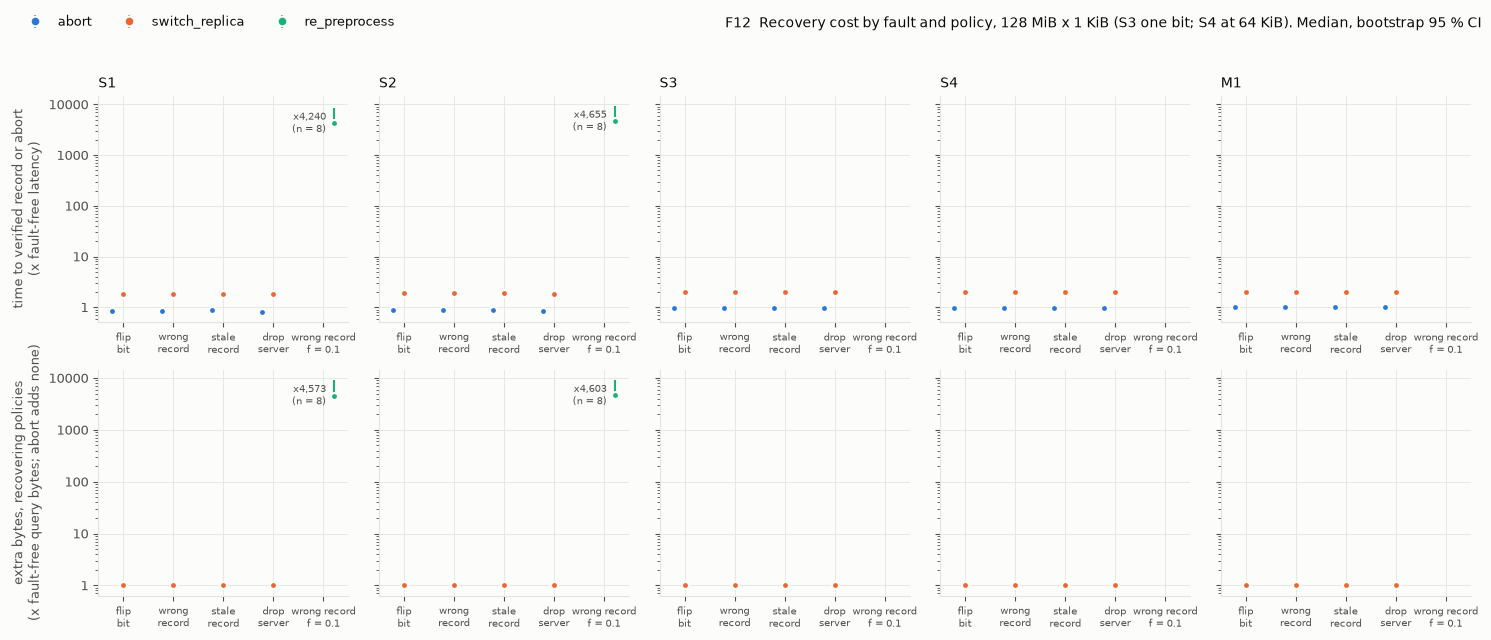

In [4]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter

# Reference palette (dataviz skill, references/palette.md), light mode; categorical slots 1 to 3 in order. The
# validator passes it, with re_preprocess's green at 2.74:1 against the surface, so its points carry direct labels
# and cells 3 and 5 print every value.
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
COLOR = {"abort": "#2a78d6", "switch_replica": "#eb6834", "re_preprocess": "#1baf7a"}
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
                     "font.size": 9, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
                     "axes.spines.top": False, "axes.spines.right": False})
FIG = repo / "docs/figures"
FIG.mkdir(parents=True, exist_ok=True)
PLAIN = FuncFormatter(lambda v, _: f"{v:g}")

def plain_log_y(ax, subs=(1.0,)):
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(LogLocator(base=10, subs=subs))
    ax.yaxis.set_major_formatter(PLAIN)
    ax.yaxis.set_minor_formatter(NullFormatter())

TICK = {"flip_answer_bit": "flip\nbit", "wrong_record": "wrong\nrecord", "stale_record": "stale\nrecord",
        "drop_server": "drop\nserver", "wrong_record, f = 0.1": "wrong record\nf = 0.1"}

def dodge_plot(ax, data, y, lo, hi, cats):
    for i, policy in enumerate(POLICIES):
        d = data[data.policy == policy]
        xs = [cats.index(f) + (i - 1) * 0.22 for f in d.fault]
        ax.errorbar(xs, d[y], yerr=[d[y] - d[lo], d[hi] - d[y]], fmt="o", ms=5, color=COLOR[policy],
                    ecolor=COLOR[policy], elinewidth=1.5, capsize=0, markeredgecolor=SURFACE, markeredgewidth=1.5,
                    label=policy)
        if policy == "re_preprocess":
            for x, v, n in zip(xs, d[y], d.n):
                ax.annotate(f"x{v:,.0f}\n(n = {n})", (x, v), xytext=(-6, 0), textcoords="offset points",
                            ha="right", va="center", fontsize=7, color=INK2)
    ax.set_xticks(range(len(cats)), [TICK[c] for c in cats])
    ax.set_xlim(-0.5, len(cats) - 0.5)

cats = FAULTS + ["wrong_record, f = 0.1"]
fig, axes = plt.subplots(2, len(VERIFIABLE), figsize=(15, 6.4), sharey="row")
for j, arm in enumerate(VERIFIABLE):
    d = f12[f12.arm == arm]
    dodge_plot(axes[0, j], d, "ratio", "ratio_lo", "ratio_hi", cats)
    axes[0, j].set_title(arm, color=INK, fontsize=10, loc="left")
    dodge_plot(axes[1, j], d[(d.policy != "abort") & (d.extra_bytes_ratio > 0)],
               "extra_bytes_ratio", "extra_lo", "extra_hi", cats)
    for ax in axes[:, j]:
        plain_log_y(ax)
        ax.tick_params(axis="x", labelsize=7)
axes[0, 0].set_ylabel("time to verified record or abort\n(x fault-free latency)")
axes[1, 0].set_ylabel("extra bytes, recovering policies\n(x fault-free query bytes; abort adds none)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper left", ncol=3, frameon=False, bbox_to_anchor=(0.01, 1.0), markerscale=1.4)
fig.suptitle("F12  Recovery cost by fault and policy, 128 MiB x 1 KiB (S3 one bit; S4 at 64 KiB). Median, bootstrap 95 % CI",
             x=0.99, ha="right", fontsize=10, color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(FIG / "F12_recovery_cost.png", dpi=200)
plt.show()

In [5]:
# F13: expected cost per query against the cheating rate f. Measured: the sweep's mean time to a verified record or
# to abort, bootstrap 95 % CI. Computed (spec 6.1) from component costs measured outside the sweep:
#   h  an honest first attempt: the f = 0 control
#   r  a rejected first attempt: the wrong_record abort trials. It differs from h, lower in S1, S2 and S4, where the
#      check fails before decoding finishes
#   s  an honest further attempt: the wrong_record switch_replica trials, whose replicas are honest
#   o  an offline phase, for re_preprocess: the flip_hint_bit offline Runs, whose client checks the whole hint
#      before it rejects the flipped bit
#   d  the detection rate: the wrong_record trials
# A cheat is caught with probability d and costs r. A missed one is accepted and costs h. After a rejection, further
# attempt k (up to 3) is reached with probability (f d)^(k-1). A rejected further attempt is taken to cost r, which the
# trials cannot measure because their replicas are honest.
#   abort:           E = (1 - f d) h + f d r
#   switch_replica:  E = abort + f d (1 + f d + (f d)^2) ((1 - f d) s + f d r)        replicas cheat at f
#   re_preprocess:   E = abort + f d (1 + f d + (f d)^2) (o + (1 - f d) h + f d r)    the same server cheats at f
def expected(policy, f, h, r, s, o, d):
    fd = f * d
    e = (1 - fd) * h + fd * r
    reach = fd * (1 + fd + fd ** 2)
    if policy == "switch_replica":
        e = e + reach * ((1 - fd) * s + fd * r)
    elif policy == "re_preprocess":
        e = e + reach * (o + (1 - fd) * h + fd * r)
    return e

def boot_mean(v):
    v = np.asarray(v, float)
    if len(v) == 0:
        return np.zeros(B)
    return v[RNG.integers(0, len(v), size=(B, len(v)))].mean(axis=1)

sweep = df[df.kind == "sweep"]
trial_wr = first[first.fault == "wrong_record"]
comp_rows, meas_rows = [], []
for arm in VERIFIABLE:
    sw = sweep[sweep.arm == arm]
    t = trial_wr[trial_wr.arm == arm]
    parts = dict(h=sw[sw.fault_prob == 0].first_s, r=t[t.policy == "abort"].time_to_end_s,
                 s=t[(t.policy == "switch_replica") & (t.attempts > 0)].recovery_s,
                 o=df[(df.kind == "offline") & (df.arm == arm) & (df.fault == "flip_hint_bit")].offline_s,
                 d=t.detected.astype(float))
    point = {k: float(v.mean()) if len(v) else 0.0 for k, v in parts.items()}
    boots = {k: boot_mean(v) for k, v in parts.items()}
    for policy in POLICIES:
        if not (sw.policy == policy).any():
            continue
        meas = sw[(sw.policy == policy) | ((sw.fault_prob == 0) & (sw.policy == "abort"))]
        for f, g in meas.groupby("fault_prob"):
            m = boot_ci(g.time_to_end_s, np.mean)
            cv = expected(policy, f, **boots)
            c = expected(policy, f, **point)
            meas_rows.append(dict(arm=arm, policy=policy, f=f, n=len(g), measured=m[0], m_lo=m[1], m_hi=m[2],
                                  computed=c, c_lo=float(np.quantile(cv, 0.025)), c_hi=float(np.quantile(cv, 0.975)),
                                  rel_err=m[0] / c - 1, agree=bool(m[1] <= np.quantile(cv, 0.975)
                                                                    and np.quantile(cv, 0.025) <= m[2])))
        for f in np.concatenate([[0.0], np.geomspace(1e-3, 1, 60)]):
            comp_rows.append(dict(arm=arm, policy=policy, f=f, computed=expected(policy, f, **point)))
    print(f"{arm:3s} components: " + ", ".join(f"{k} {point[k]:.4g}" + ("" if k == "d" else " s") + f" (n={len(parts[k])})"
                                              for k in parts))
f13 = pd.DataFrame(meas_rows)
curves = pd.DataFrame(comp_rows)
print("\nMean time per query (s): measured in the sweep against computed from components, 95 % CIs; "
      "agree = the two intervals overlap")
print(f13.round(4).to_string(index=False))
checked = f13[f13.f > 0]          # f = 0 is the control that h comes from
print("\nAt f > 0, per policy: measured points, how many agree, and the largest |measured / computed - 1|")
print(checked.groupby("policy", sort=False).agg(points=("agree", "size"), agree=("agree", "sum"),
                                                 max_rel_err=("rel_err", lambda e: e.abs().max())).round(4).to_string())

S1  components: h 0.03233 s (n=1000), r 0.02759 s (n=100), s 0.03194 s (n=100), o 137 s (n=3), d 1 (n=200)


S2  components: h 0.04232 s (n=1000), r 0.03707 s (n=100), s 0.04237 s (n=100), o 196.8 s (n=3), d 1 (n=200)
S3  components: h 2.011 s (n=50), r 1.96 s (n=30), s 2.002 s (n=30), o 0 s (n=0), d 1 (n=60)
S4  components: h 1.284 s (n=50), r 1.246 s (n=30), s 1.286 s (n=30), o 0 s (n=0), d 1 (n=60)


M1  components: h 0.03721 s (n=1000), r 0.0374 s (n=100), s 0.03707 s (n=100), o 0 s (n=0), d 1 (n=200)

Mean time per query (s): measured in the sweep against computed from components, 95 % CIs; agree = the two intervals overlap
arm         policy    f    n  measured    m_lo    m_hi  computed    c_lo    c_hi  rel_err  agree
 S1          abort 0.00 1000    0.0323  0.0323  0.0323    0.0323  0.0323  0.0323   0.0000   True
 S1          abort 0.01 1000    0.0323  0.0322  0.0323    0.0323  0.0323  0.0323  -0.0003   True
 S1          abort 0.10 1000    0.0318  0.0317  0.0319    0.0319  0.0318  0.0319  -0.0011   True
 S1          abort 0.50 1000    0.0302  0.0300  0.0303    0.0300  0.0299  0.0301   0.0067   True
 S1          abort 1.00 1000    0.0279  0.0279  0.0279    0.0276  0.0275  0.0278   0.0128  False
 S1 switch_replica 0.00 1000    0.0323  0.0323  0.0323    0.0323  0.0323  0.0323   0.0000   True
 S1 switch_replica 0.01 1000    0.0326  0.0325  0.0329    0.0326  0.0326  0.0326   0.0012  

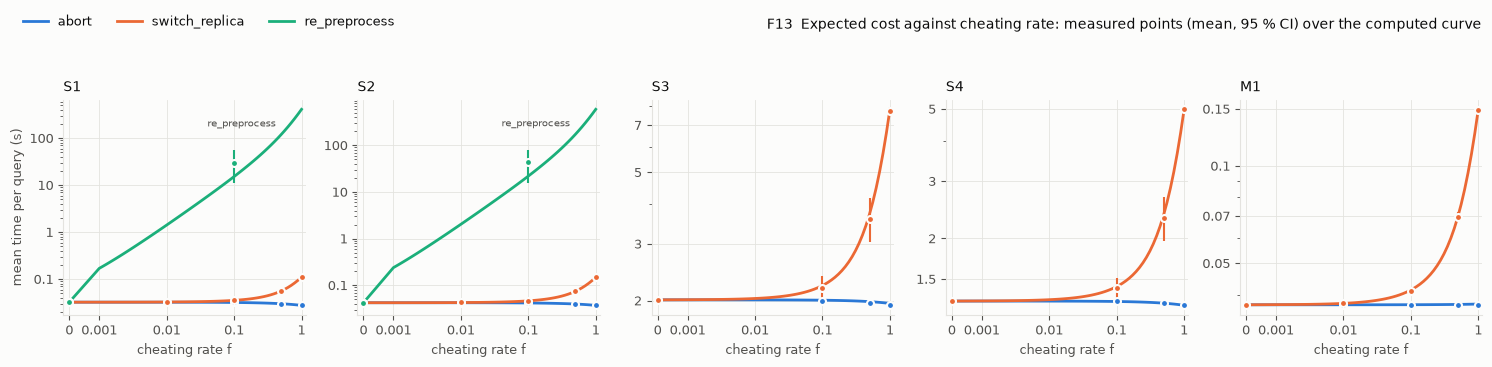

In [6]:
fig, axes = plt.subplots(1, len(VERIFIABLE), figsize=(15, 3.6), sharey=False)
for j, arm in enumerate(VERIFIABLE):
    ax = axes[j]
    for policy in POLICIES:
        c = curves[(curves.arm == arm) & (curves.policy == policy)]
        if len(c) == 0:
            continue
        ax.plot(c.f, c.computed, color=COLOR[policy], lw=2, label=f"{policy}, computed")
        m = f13[(f13.arm == arm) & (f13.policy == policy)]
        ax.errorbar(m.f, m.measured, yerr=[m.measured - m.m_lo, m.m_hi - m.measured], fmt="o", ms=5,
                    color=COLOR[policy], elinewidth=1.5, capsize=0, markeredgecolor=SURFACE, markeredgewidth=1.5)
        if policy == "re_preprocess":
            ax.annotate("re_preprocess", (0.5, c[c.f <= 0.5].computed.iloc[-1]), xytext=(-4, 6),
                        textcoords="offset points", ha="right", fontsize=7, color=INK2)
    # Linear from 0 to 0.001, where no rate was measured, then logarithmic.
    ax.set_xscale("symlog", linthresh=1e-3, linscale=0.4)
    ax.set_xlim(-2e-4, 1.15)
    ax.set_xticks([0, 1e-3, 1e-2, 1e-1, 1], ["0", "0.001", "0.01", "0.1", "1"])
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_title(arm, color=INK, fontsize=10, loc="left")
    ax.set_xlabel("cheating rate f")
for ax in axes:   # ticks after autoscaling: decades over a wide range, 1-1.5-2-3-5-7 within one or two decades
    ax.set_yscale("log")
    lo, hi = ax.get_ylim()
    plain_log_y(ax, subs=(1.0,) if hi / lo > 100 else (1.0, 1.5, 2.0, 3.0, 5.0, 7.0))
axes[0].set_ylabel("mean time per query (s)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, [l.replace(", computed", "") for l in labels], loc="upper left", ncol=3, frameon=False,
           bbox_to_anchor=(0.01, 1.02))
fig.suptitle("F13  Expected cost against cheating rate: measured points (mean, 95 % CI) over the computed curve",
             x=0.99, ha="right", fontsize=10, color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(FIG / "F13_expected_cost.png", dpi=200)
plt.show()

In [7]:
# What the reruns changed: each rerun Run in every run that measured it, notebook 10 first.
def run_summary(run_dir, name):
    m = next(json.loads(l) for l in (run_dir / "manifest.jsonl").read_text().splitlines()
             if json.loads(l)["name"] == name)
    rs = [json.loads(l) for l in (run_dir / f"{name}.jsonl").read_text().splitlines()]
    rs = [r for r in rs if not r["is_warmup"]]
    honest = [r for r in rs if not r["faulted"]]
    per_attempt = [r["metrics"]["recovery_s"] / r["recovery_attempts"] for r in rs if r["recovery_attempts"]]
    return dict(query_gen_s=np.median([r["metrics"]["query_gen_s"] for r in rs]),
                honest_query_gen_s=np.median([r["metrics"]["query_gen_s"] for r in honest]) if honest else np.nan,
                recovery_per_attempt_s=np.median(per_attempt) if per_attempt else np.nan,
                peak_gib=m["peak_footprint_bytes"] / 2**30)

NOTEBOOK = {RUNS[0].name: "nb 10", RUNS[1].name: "nb 12", RUNS[2].name: "nb 13"}
rows = []
for name in sorted(n for n, d in source.items() if d != RUNS[0].name):
    for run_dir in RUNS:
        if (run_dir / f"{name}.jsonl").exists():
            rows.append(dict(run=name.replace("-db134217728", "").replace("-wrong_record", ""),
                             source=NOTEBOOK[run_dir.name], **run_summary(run_dir, name)))
cmp = pd.DataFrame(rows).pivot(index="run", columns="source")
print("Medians per Run in each run that measured it (the last one is analysed); peak footprint per Run")
print(cmp.round(4).to_string(na_rep="-"))

Medians per Run in each run that measured it (the last one is analysed); peak footprint per Run
                                                   query_gen_s                 honest_query_gen_s                 recovery_per_attempt_s                 peak_gib                
source                                                   nb 10   nb 12   nb 13              nb 10   nb 12   nb 13                  nb 10   nb 12   nb 13    nb 10   nb 12   nb 13
run                                                                                                                                                                              
sweep-M1-rb1024-switch_replica-p0_01-cheat              0.0000  0.0000       -             0.0000  0.0000       -                 0.0736  0.0372       -   0.9879  1.0011       -
sweep-M1-rb1024-switch_replica-p0_1-cheat               0.0000  0.0000       -             0.0000  0.0000       -                 0.0742  0.0372       -   1.0944  1.0235       -
sweep-M1-rb102